# Test Trapezoids
As per Reviewer 1 comment: what is the improvement with respect to FAO-56/Rallo models?
The idea is this:
- Take test ETa data
- Measure the distance to our Trapezoid line
- Measure the distance to FAO-56/Rallo line
- Compare the two distances, regarding them as errors on measures

If we consider the FAO-56/Rallo as a baseline, we can calculate a ``relative improvement'' with:
$$
I(\%) = \frac{E_{baseline}-E_{ML}}{E_{baseline}}
$$

In [96]:
import pandas as pd
import numpy as np
import toml
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
from pathlib import Path

ROOT = Path("../")
DATABASE = ROOT / "data"
EXPERIMENTS = [
    "ca_er1_paper",
    "castelvetrano_paper",
    "us_arm_paper",
    "us_cf1_paper",
    "us_ne1_paper",
    "villabate_paper",
]

FIELDS_CSV_COLUMN = {
    "ca_er1": "CA_ER1",
    "castelvetrano": "Castelvetrano",
    "us_arm": "US_ARM",
    "us_cf1": "US_CF1",
    "us_ne1": "US_Ne1",
    "villabate": "Villabate",
}

trapezoids = pd.read_csv(
    DATABASE / "external" / "trapezi.csv", sep=";", header=0, index_col=0, parse_dates=True, dayfirst=True)

## Compare Trapezoidal Series

In [81]:
#Extend the trapezoidal series back 10 years

# Extract only the day and month part of the index
trapezoids['day_month'] = trapezoids.index.strftime('%m-%d')

# Extend the date range back 10 years
extended_date_range = pd.date_range(start='2000-01-01', end='2025-12-31', freq='D')
extended_df = pd.DataFrame(index=extended_date_range)

# Extract day and month part of the extended index
extended_df['day_month'] = extended_df.index.strftime('%m-%d')

# Merge the extended date range with the original data on day and month
trapezoids_extended = extended_df.merge(trapezoids, on='day_month', how='left')

# Set the index back to the date range
trapezoids_extended.set_index(extended_date_range, inplace=True)
trapezoids_extended.drop(columns=['day_month'], inplace=True)
# Drop bissextile day
trapezoids_extended.ffill(inplace=True)



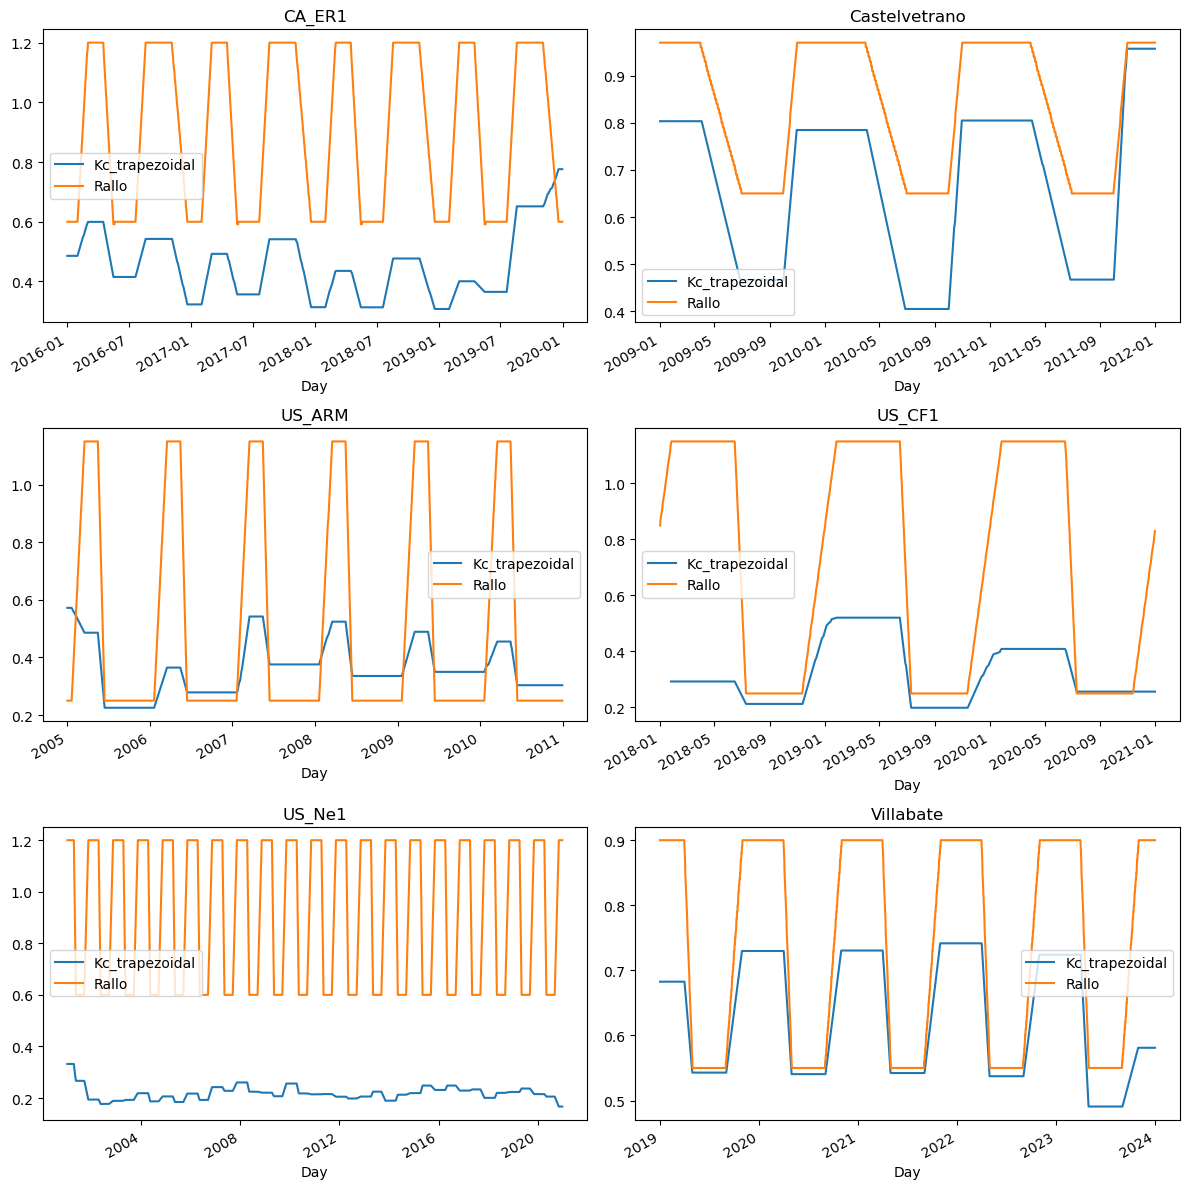

In [218]:
def plot_trapezoids(field, ax=None):
    trapezoidal_villabate = pd.read_pickle(DATABASE / f"{field}_paper/data/postprocessed/trapezoidal.pickle")
    trapezoidal_villabate.drop("Error", axis=1, inplace=True)
    trapezoidal_villabate.set_index("Day", inplace=True)
    allen_villabate = trapezoids_extended.loc[trapezoidal_villabate.index, f'Allen_{FIELDS_CSV_COLUMN[field]}']
    trapezoidal_villabate["Rallo"] = allen_villabate.values
    trapezoidal_villabate.plot(ax=ax)

fig, axs = plt.subplots(3, 2, figsize=(12, 12), layout="tight")
axs = axs.flatten()
for i, field in enumerate(FIELDS_CSV_COLUMN.keys()):
    plot_trapezoids(field, axs[i])
    axs[i].set_title(f"{FIELDS_CSV_COLUMN[field]}")


In [208]:
def get_experiment_folds(experiment):
    with open(DATABASE / experiment / "config.toml", "r") as f:
        config = toml.load(f)

    return config["preprocess"]["folds"]


def extract_test_points(field, fold, train=False, predictions=False):
    test_data = DATABASE / f"{field}_paper/data/preprocessed" / f"test_fold_{fold}.pickle"
    train_data = DATABASE / f"{field}_paper/data/preprocessed" / f"train_fold_{fold}.pickle"
    raw_data = DATABASE / f"{field}_paper/data/raw" / f"data_{field}.csv"
    test_days = pd.read_pickle(test_data).index
    if train:
        test_days = test_days.append(pd.read_pickle(train_data).index)
    if predictions:
        predictions = pd.read_pickle(DATABASE / f"{field}_paper/data/predictions" / f"kc_predicted.pickle")
        return predictions["Kc"].dropna()
    df = pd.read_csv(
        raw_data, index_col=0, header=0, sep=";", parse_dates=True, dayfirst=True
        )
    kc = df.loc[test_days, "Kc*Ks"].dropna()
    if fold == 0:
        total_days = len(df)
        print(f"There are {len(test_days)} test days out of {total_days} total days.")
    return kc


def get_trapezoidal_series(field, days):
    field_col = FIELDS_CSV_COLUMN[field]
    trpz_file = f"{field}_paper/data/postprocessed/trapezoidal.pickle"
    trpz_ml = pd.read_pickle(DATABASE / trpz_file).set_index("Day").dropna(subset=["Kc_trapezoidal"])
    days_inliers = [day for day in days if day in trpz_ml.index]
    trpz_ml = trpz_ml.loc[days_inliers, "Kc_trapezoidal"]
    trpz_fao = trapezoids_extended.loc[days_inliers, f"Allen_{field_col}"]
    trpz_rallo = trapezoids_extended.loc[days_inliers, f"Rallo_{field_col}"]
    return days_inliers, trpz_fao, trpz_rallo, trpz_ml


kc = extract_test_points("villabate", 0, predictions=True)
dd, t1, t2, t3 = get_trapezoidal_series("villabate", kc.index)
kc = kc.loc[dd]
for t in [t1, t2, t3]:
    print(f"{len(t)} - {len(t.dropna())}")
    root_mean_squared_error(kc.values, t.values)

1796 - 1796
1796 - 1796
1796 - 1796


In [206]:
f = "villabate"
predictions = pd.read_pickle(DATABASE / f"{f}_paper/data/predictions" / f"kc_predicted.pickle")
predictions

,Kc,Source
Day,,
2019-01-01,0.603623,Predicted
2019-01-02,0.562532,Predicted
2019-01-03,0.846035,Predicted
2019-01-04,1.067342,Predicted
2019-01-05,0.818214,Predicted
...,...,...
2023-12-27,1.053333,Measured
2023-12-28,0.773333,Measured
2023-12-29,0.545455,Measured


In [209]:
errors = {}
for experiment in EXPERIMENTS:
    field = "_".join(experiment.split("_")[:-1])
    print(f"\nExperiment: {field}")
    n_folds = get_experiment_folds(experiment)
    fold_errors = np.zeros((n_folds, 3))
    for fold in range(n_folds):
        kc = extract_test_points(field, fold, train=True)
        days, fao, rallo, ml = get_trapezoidal_series(field, kc.index)
        # Filter out days with outliers
        kc = kc.loc[days]
        for j, trpz in enumerate([fao, rallo, ml]):
            rmse = root_mean_squared_error(kc.values, trpz.values)
            fold_errors[fold, j] = rmse
            print(f"{rmse}", end=" | ")
        print()
    errors[field] = fold_errors.mean(axis=0)

errors = pd.DataFrame().from_dict(errors, orient='index', columns=["Allen", "Rallo", "ML"])


Experiment: ca_er1
There are 1160 test days out of 1461 total days.
0.5966253229171101 | 0.5497699005081991 | 0.2529863379425055 | 
0.5966253229171101 | 0.5497699005081991 | 0.2529863379425055 | 
0.5966253229171101 | 0.5497699005081991 | 0.2529863379425055 | 

Experiment: castelvetrano
There are 622 test days out of 1095 total days.
0.33622275537145946 | 0.2047344212564226 | 0.23596962237620392 | 
0.33622275537145946 | 0.2047344212564226 | 0.23596962237620392 | 
0.33622275537145946 | 0.2047344212564226 | 0.23596962237620392 | 
0.33622275537145946 | 0.2047344212564226 | 0.23596962237620395 | 

Experiment: us_arm
There are 1858 test days out of 2191 total days.
0.3850469496407402 | 0.40738643884517195 | 0.19546580642819064 | 
0.3850469496407402 | 0.40738643884517195 | 0.19546580642819064 | 
0.3850469496407402 | 0.40738643884517195 | 0.19546580642819064 | 
0.3850469496407402 | 0.40738643884517195 | 0.19546580642819067 | 

Experiment: us_cf1
There are 809 test days out of 1096 total days.

In [211]:
errors["Allen Improv"] = errors.apply(lambda x: (x["Allen"] - x["ML"]) / x["Allen"] * 100 , axis=1)
errors["Rallo Improv"] = errors.apply(lambda x: (x["Rallo"] - x["ML"]) / x["Rallo"] * 100 , axis=1)
errors

,Allen,Rallo,ML,Allen Improv,Rallo Improv
ca_er1,0.596625,0.549770,0.252986,57.597117,53.983232
castelvetrano,0.336223,0.204734,0.235970,29.817474,-15.256448
us_arm,0.385047,0.407386,0.195466,49.235851,52.019560
us_cf1,0.552827,0.575819,0.209693,62.068877,63.583463
us_ne1,0.784796,0.740752,0.135209,82.771397,81.746997
villabate,0.243498,0.161116,0.172300,29.239564,-6.942182
